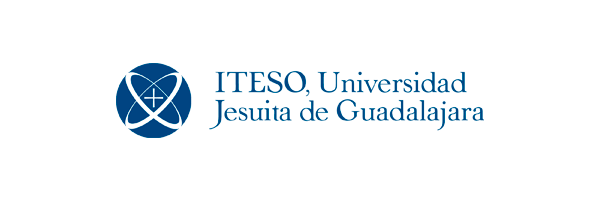

# Reporte de Prácticas de Perceptrón Multicapa (Clasificación)

## Tarea 9

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 27 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 3: clasificación binaria con `data1.txt`](#practica3)
    - 2.1 [Definición del problema](#p3-definicion)
    - 2.2 [Descripción del algoritmo](#p3-algoritmo)
    - 2.3 [Implementación](#p3-implementacion)
    - 2.4 [Pruebas y resultados](#p3-pruebas)
    - 2.5 [Análisis y conclusiones de la práctica](#p3-analisis)
3. [Práctica 4: clasificación multiclase con `vinos.txt`](#practica4)
    - 3.1 [Definición del problema](#p4-definicion)
    - 3.2 [Descripción del algoritmo](#p4-algoritmo)
    - 3.3 [Implementación](#p4-implementacion)
    - 3.4 [Pruebas y resultados](#p4-pruebas)
    - 3.5 [Análisis y conclusiones de la práctica](#p4-analisis)
4. [Conclusiones](#conclusiones)
    - 4.1 [Conclusiones personales](#conclusiones-personales)
    - 4.2 [Conclusiones generales](#conclusiones-generales)

<a id="introduccion"></a>

## 1. Introducción y objetivos

En la Tarea 8 usamos el **perceptrón multicapa** (MLP) para **regresión**: la red predecía un número, el precio de un activo. En esta tarea usamos la misma red para **clasificación**: ahora la salida no es un número cualquiera, sino la **clase** a la que pertenece cada muestra.

La estructura del MLP es la misma: una **capa de entrada** con las variables de cada muestra, una o más **capas ocultas** con funciones de activación no lineales y una **capa de salida**. Lo que cambia es la capa de salida y la forma de medir el error:

- En la **clasificación binaria** (dos clases) la salida es **una sola neurona logística** que da la probabilidad de que la muestra sea de la clase 1. Si esa probabilidad es de 0.5 o más, la red asigna la clase 1; si no, la clase 0.
- En la **clasificación multiclase** (más de dos clases) hay **una neurona de salida por clase** con la función **softmax**, que convierte las salidas en probabilidades que suman 1. La red asigna la clase con mayor probabilidad.
- En lugar del error cuadrático se minimiza la **entropía cruzada** (*log-loss*), que castiga más cuando la red está muy segura de una clase equivocada.

Los pesos se siguen ajustando con **retropropagación del error**. Las capas ocultas permiten que la **frontera de decisión** (la línea o superficie que separa las clases) sea curva, algo que un perceptrón simple no puede lograr.

Para evaluar un clasificador no basta con la exactitud. Se usa la **matriz de confusión**, que cuenta los aciertos y errores por clase, junto con la **precisión**, el **recall** y el **F1**.

**Objetivo general:** implementar perceptrones multicapa de clasificación con `MLPClassifier` de scikit-learn, para un problema de dos clases y uno de tres clases, y evaluar su desempeño con la matriz de confusión y las métricas de clasificación.

**Objetivos específicos**
- Entrenar un MLP para separar dos clases en el plano y graficar su frontera de decisión (Práctica 3).
- Comparar arquitecturas, funciones de activación y tipos de normalización, y elegir el mejor modelo.
- Clasificar puntos nuevos con el modelo entrenado.
- Extender el MLP a un problema de tres clases con 13 variables químicas de vinos (Práctica 4).
- Revisar la curva de pérdida y las métricas por clase y promedio (macro).
- Clasificar vinos nuevos con la red entrenada.

<a id="practica3"></a>

## 2. Práctica 3: clasificación binaria con `data1.txt`

<a id="p3-definicion"></a>

### 2.1 Definición del problema

El archivo `data1.txt` tiene **100 muestras**. Cada muestra tiene **dos variables de entrada** ($x_1$ = Variable 1, $x_2$ = Variable 2, con valores aproximadamente entre 30 y 100) y una **clase** en la tercera columna, que vale 0 o 1. Hay **40 muestras de la clase 0** y **60 de la clase 1**. En la gráfica las clases no se separan con una línea recta perfecta: hay una zona donde se mezclan.

Es un problema de **clasificación binaria supervisada**: cada muestra trae su clase correcta y la red debe aprender a asignarla a partir de $x_1$ y $x_2$. Se busca:

1. Entrenar un MLP con el **90 % inicial** de los datos (90 muestras) y dejar el **10 % final** (10 muestras) como referencia de datos no vistos.
2. Predecir la clase de las 100 muestras y comparar las clases reales con las predichas en el plano, junto con la **frontera de decisión**.
3. Evaluar con la matriz de confusión, la exactitud, la precisión, el recall y el F1 (clase positiva = 1).
4. Analizar el efecto de la arquitectura, la función de activación y la normalización de las entradas.
5. Usar el modelo para clasificar puntos nuevos definidos por el equipo.

<a id="p3-algoritmo"></a>

### 2.2 Descripción del algoritmo

**Esquema del MLP** (código base: una capa oculta de 50 neuronas con `tanh`)

```
  Capa de entrada         Capa oculta (tanh)            Capa de salida (logística)

  x1 (Variable 1) ──┐     ┌───────────────┐
                    ├───► │  50 neuronas  │ ───►  p = P(clase 1 | x) ───►  clase = 1 si p ≥ 0.5
  x2 (Variable 2) ──┘     └───────────────┘                                clase = 0 si p < 0.5
        W1 (2x50), b1                   W2 (50x1), b2
```

Esta red tiene **201 parámetros** (pesos + sesgos). Con una capa oculta de 5 neuronas tendría solo 21.

1. **Carga y separación:** `X` son las columnas 0 y 1 y `y` la columna 2. Las primeras $n_{dat} = \text{round}(0.9 \cdot 100) = 90$ muestras son de entrenamiento.
2. **Normalización (opcional):** como las variables valen entre 30 y 100, activaciones como `tanh` y `logistic` pueden **saturarse** (por ejemplo, $\tanh(50) \approx 1$) y dejar de aprender. Se prueban dos escalas, ajustadas solo con las 90 muestras de entrenamiento:
$$\text{Estandarización: } \tilde{x} = \frac{x - \mu}{\sigma} \qquad\qquad \text{Min-max: } \tilde{x} = \frac{x - x_{min}}{x_{max} - x_{min}}$$
3. **Propagación hacia adelante:** la capa oculta calcula $a = f(W_1 x + b_1)$, con $f$ = `identity`, `logistic`, `tanh` o `relu`. La salida es una neurona logística:
$$z = W_2\,a + b_2, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
   $p$ se interpreta como la probabilidad de que la muestra sea de la clase 1.
4. **Regla de decisión:** $\hat{y} = 1$ si $p \ge 0.5$ y $\hat{y} = 0$ si $p < 0.5$. La **frontera de decisión** es el conjunto de puntos donde $p = 0.5$. Si la capa oculta usa `identity`, toda la red equivale a una regresión logística y la frontera es **una línea recta**; con `logistic`, `tanh` o `relu` la frontera puede ser curva.
5. **Función de pérdida:** `MLPClassifier` minimiza la **entropía cruzada binaria** más una penalización L2 ($\alpha = 0.0001$):
$$L = -\frac{1}{n}\sum_{i=1}^{n}\Big[\,y_i \log p_i + (1 - y_i)\log(1 - p_i)\,\Big] + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
   Si la clase real es 1 y la red da $p$ cercano a 0, el término $\log p$ es muy negativo y la pérdida crece mucho.
6. **Retropropagación y optimización:** con la logística y la entropía cruzada, el error de la salida queda simplemente $\delta = p - y$. Ese error se manda hacia atrás, $\delta_{oculta} = W_2^{\top}\delta \odot f'(z_{oculta})$, para obtener los gradientes de todos los pesos. El optimizador **L-BFGS** (`solver='lbfgs'`) los actualiza hasta converger o llegar a `max_iter`.
7. **Evaluación:** con la matriz de confusión (filas = clase real, columnas = clase predicha)

| | Predicho 0 | Predicho 1 |
|---|---|---|
| **Real 0** | VN (verdaderos negativos) | FP (falsos positivos) |
| **Real 1** | FN (falsos negativos) | VP (verdaderos positivos) |

   se calculan:
$$\text{Exactitud} = \frac{VP + VN}{VP + VN + FP + FN}, \quad \text{Precisión} = \frac{VP}{VP + FP}, \quad \text{Recall} = \frac{VP}{VP + FN}, \quad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$
   La precisión responde "de lo que la red llamó clase 1, ¿cuánto sí lo era?" y el recall "de todo lo que era clase 1, ¿cuánto encontró?". El F1 combina las dos.
8. **Frontera de decisión y casos nuevos:** se predice la clase en una malla de puntos que cubre el plano y se colorea cada región según la clase predicha. Los puntos nuevos se clasifican con la misma normalización que se usó al entrenar.

**Pseudocódigo**
```
INICIO
    data <- leer data1.txt                      // 100 filas: x1, x2, clase
    X <- columnas 0 y 1          y <- columna 2
    ndat <- round(0.9 * 100)                    // 90
    SI se normaliza ENTONCES
        ajustar el escalador (z-score o min-max) con X[0..ndat-1]
        X <- escalador(X)
    FIN SI
    red <- MLPClassifier(capas ocultas, activación, solver = 'lbfgs')
    REPETIR hasta converger o llegar a max_iter          // red.fit(X[0..ndat-1], y[0..ndat-1])
        a <- f(W1 * x + b1)                     // capa oculta
        p <- 1 / (1 + exp(-(W2 * a + b2)))      // probabilidad de clase 1
        L <- entropía cruzada binaria + penalización L2
        δ <- p - y                              // error de la salida
        gradientes <- retropropagación de δ
        actualizar W y b con L-BFGS
    FIN REPETIR
    Yg <- 1 si p >= 0.5, si no 0  para las 100 muestras    // red.predict(X)
    Calcular matriz de confusión, exactitud, precisión, recall y F1
    Graficar clases reales vs. predichas y la frontera de decisión
    Para cada punto nuevo: normalizarlo igual y obtener su clase y su p
FIN
```

<a id="p3-implementacion"></a>

### 2.3 Implementación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
warnings.filterwarnings('ignore')

# Cargar datos: columnas 0 y 1 = entradas, columna 2 = clase (0 o 1)
data = np.loadtxt('data1.txt', delimiter=',')
X = data[:, :2]                 # variables de entrada (Variable 1 y Variable 2)
y = data[:, 2].astype(int)      # clase real de cada muestra
print('Muestras:', len(y), '| Clase 0:', (y == 0).sum(), '| Clase 1:', (y == 1).sum())

Muestras: 100 | Clase 0: 40 | Clase 1: 60


#### Procedimiento
Se sigue el código base `MLP_3.py`: se entrena con el **90 % inicial** (90 muestras) y se evalúa sobre las 100 muestras con matriz de confusión, exactitud, precisión, recall y F1 (clase positiva = 1). Se agrega también la exactitud en el 10 % final (10 muestras) como referencia.

Se varían tres cosas: **arquitectura** (5 opciones), **función de activación** (`identity`, `logistic`, `tanh`, `relu`) y **normalización** (ninguna, estandarización y min-max, ajustadas solo con los datos de entrenamiento). Son 5 × 4 × 3 = **60 configuraciones**, todas con `solver='lbfgs'` y `random_state=42` para que los resultados sean reproducibles.

In [2]:
# Opciones a probar: 5 arquitecturas x 4 activaciones x 3 normalizaciones = 60 configuraciones
archs = [(5,), (10,), (50,), (10, 5), (20, 10, 5)]   # neuronas por capa oculta
activaciones = ['identity', 'logistic', 'tanh', 'relu']
normalizaciones = ['ninguna', 'estandar', 'minmax']

def entrenar(arch, act, norm):
    # 1) Elegir el escalador. Se ajusta solo con los 90 datos de entrenamiento
    #    para no filtrar información de las últimas 10 muestras.
    esc = {'ninguna': None, 'estandar': StandardScaler(), 'minmax': MinMaxScaler()}[norm]
    if esc is not None:
        esc.fit(X[:90])
    Xe = X if esc is None else esc.transform(X)   # entradas ya normalizadas (o sin cambio)

    # 2) Crear el MLP. solver='lbfgs' funciona bien con pocos datos;
    #    random_state=42 hace los resultados reproducibles.
    red = MLPClassifier(hidden_layer_sizes=arch, activation=act, solver='lbfgs',
                        max_iter=2000, random_state=42)

    # 3) Entrenar con el 90 % inicial y predecir sobre las 100 muestras
    red.fit(Xe[:90], y[:90])
    return esc, red, red.predict(Xe)

rows = []
for a in archs:
    for act in activaciones:
        for norm in normalizaciones:
            esc, red, Yg = entrenar(a, act, norm)
            rows.append(dict(
                Arquitectura=str(a), Activacion=act, Normalizacion=norm,
                # Parámetros = todos los pesos + todos los sesgos (bias) de la red
                Parametros=sum(c.size for c in red.coefs_) + sum(c.size for c in red.intercepts_),
                # Métricas sobre las 100 muestras (clase positiva = 1)
                Exactitud=accuracy_score(y, Yg), Precision=precision_score(y, Yg, zero_division=0),
                Recall=recall_score(y, Yg), F1=f1_score(y, Yg),
                # Referencia: exactitud solo en el 10 % final (10 muestras)
                Exactitud_10pct_final=accuracy_score(y[90:], Yg[90:])))

res = pd.DataFrame(rows)   # tabla con las 60 configuraciones
print('Configuraciones probadas:', len(res))

Configuraciones probadas: 60


<a id="p3-pruebas"></a>

### 2.4 Pruebas y resultados

#### Tabla comparativa (60 configuraciones)

In [3]:
pd.set_option('display.max_rows', 100, 'display.width', 200)
tabla = res.round(3)
tabla

,Arquitectura,Activacion,Normalizacion,Parametros,Exactitud,Precision,Recall,F1,Exactitud_10pct_final
0,"(5,)",identity,ninguna,21,0.90,0.917,0.917,0.917,0.9
1,"(5,)",identity,estandar,21,0.90,0.917,0.917,0.917,0.9
2,"(5,)",identity,minmax,21,0.90,0.917,0.917,0.917,0.9
3,"(5,)",logistic,ninguna,21,0.94,0.950,0.950,0.950,0.9
4,"(5,)",logistic,estandar,21,0.99,1.000,0.983,0.992,0.9
5,"(5,)",logistic,minmax,21,1.00,1.000,1.000,1.000,1.0
6,"(5,)",tanh,ninguna,21,0.95,0.937,0.983,0.959,1.0
7,"(5,)",tanh,estandar,21,1.00,1.000,1.000,1.000,1.0
8,"(5,)",tanh,minmax,21,0.99,1.000,0.983,0.992,0.9
9,"(5,)",relu,ninguna,21,0.94,0.950,0.950,0.950,0.9


#### Resumen por factor (F1 promedio)

In [4]:
print('Por activación × normalización')
display(res.groupby(['Activacion', 'Normalizacion']).F1.mean().round(3).unstack())
print('Por arquitectura')
display(res.groupby('Arquitectura').F1.mean().round(3))

Por activación × normalización


Normalizacion,estandar,minmax,ninguna
Activacion,,,
identity,0.917,0.917,0.917
logistic,0.993,1.000,0.918
relu,0.993,0.987,0.963
tanh,0.997,0.995,0.891


Por arquitectura


Arquitectura
(10, 5)        0.950
(10,)          0.928
(20, 10, 5)    0.967
(5,)           0.965
(50,)          0.976
Name: F1, dtype: float64

#### Mejor modelo y caso de bajo desempeño

In [5]:
# Mejor: mayor F1; si hay empate, el de menos parámetros
orden = res.sort_values(['F1', 'Parametros'], ascending=[False, True])
mejor = orden.iloc[0]
malo = res.sort_values('F1').iloc[0]
display(pd.DataFrame([mejor, malo], index=['Mejor', 'Bajo desempeño']).round(3))
print('Configuraciones con F1 = 1.0:', (res.F1 == 1.0).sum(), 'de', len(res))

,Arquitectura,Activacion,Normalizacion,Parametros,Exactitud,Precision,Recall,F1,Exactitud_10pct_final
Mejor,"(5,)",logistic,minmax,21,1.0,1.0,1.0,1.00,1.0
Bajo desempeño,"(10,)",logistic,ninguna,41,0.6,0.6,1.0,0.75,0.9


Configuraciones con F1 = 1.0: 16 de 60


#### Gráficas de clasificación (clases reales vs. predichas)
Solo se grafican el mejor modelo y el de bajo desempeño. Igual que el código base, pero con la frontera de decisión de fondo.

In [6]:
def graficar(titulo, arch, act, norm):
    # Entrenar el modelo y obtener sus predicciones (Yg) sobre las 100 muestras
    esc, red, Yg = entrenar(arch, act, norm)

    # Frontera de decisión: se predice la clase en una malla de puntos que cubre el plano
    gx, gy = np.meshgrid(np.linspace(25, 105, 300), np.linspace(25, 105, 300))
    malla = np.c_[gx.ravel(), gy.ravel()]
    Z = red.predict(malla if esc is None else esc.transform(malla))   # aplicar la misma normalización

    plt.figure(figsize=(8, 6))
    # Fondo: azul claro = región clase 0, rosa = región clase 1
    plt.contourf(gx, gy, Z.reshape(gx.shape), levels=[-.5, .5, 1.5], colors=['#cfe3ff', '#ffd6d6'], alpha=.6)

    # Separar las muestras por clase real y por clase predicha
    G0, G1 = X[y == 0], X[y == 1]
    G0p, G1p = X[Yg == 0], X[Yg == 1]
    plt.plot(G0[:, 0], G0[:, 1], 'bo', markersize=10, label='Grupo 0 (Real)')
    plt.plot(G1[:, 0], G1[:, 1], 'ro', markersize=10, label='Grupo 1 (Real)')
    plt.plot(G0p[:, 0], G0p[:, 1], 'cX', markersize=8, label='Grupo 0 (Predicho)')
    plt.plot(G1p[:, 0], G1p[:, 1], 'mX', markersize=8, label='Grupo 1 (Predicho)')

    # Título con las métricas del modelo
    plt.title('%s\nExactitud=%.2f  Precisión=%.2f  Recall=%.2f  F1=%.2f' % (
        titulo, accuracy_score(y, Yg), precision_score(y, Yg, zero_division=0), recall_score(y, Yg), f1_score(y, Yg)), fontsize=10)
    plt.xlabel('Variable 1'); plt.ylabel('Variable 2'); plt.xlim(25, 105); plt.ylim(25, 105)
    plt.legend(fontsize=8, loc='lower left'); plt.grid(True); plt.show()

    # Matriz de confusión: filas = clase real, columnas = clase predicha
    print('Matriz de confusión (filas = real, columnas = predicho):'); print(confusion_matrix(y, Yg))
    return esc, red   # se devuelven para reutilizar el modelo en los casos de prueba

##### Caso 1: mejor modelo

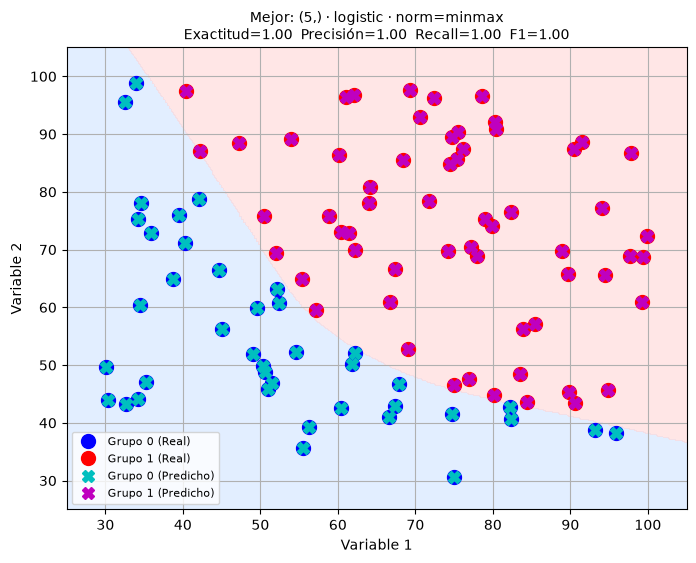

Matriz de confusión (filas = real, columnas = predicho):
[[40  0]
 [ 0 60]]


In [7]:
esc_b, red_b = graficar('Mejor: %s · %s · norm=%s' % (mejor.Arquitectura, mejor.Activacion, mejor.Normalizacion),
                        eval(mejor.Arquitectura), mejor.Activacion, mejor.Normalizacion)

##### Caso 2: bajo desempeño

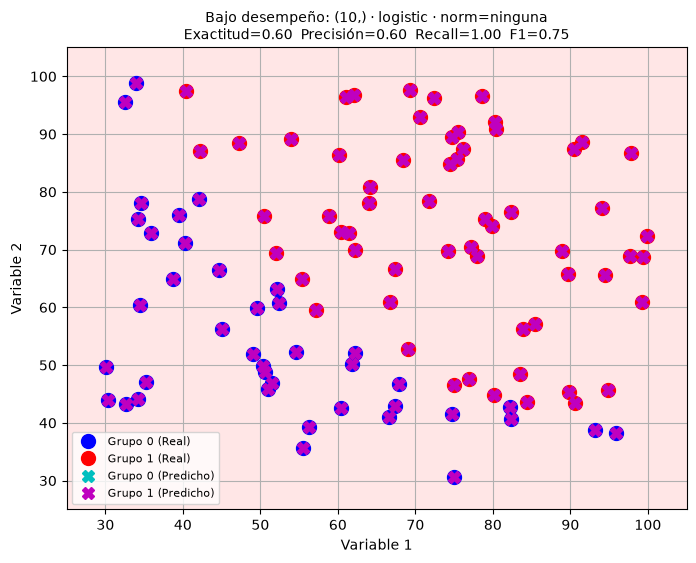

Matriz de confusión (filas = real, columnas = predicho):
[[ 0 40]
 [ 0 60]]


In [8]:
esc_m, red_m = graficar('Bajo desempeño: %s · %s · norm=%s' % (malo.Arquitectura, malo.Activacion, malo.Normalizacion),
                        eval(malo.Arquitectura), malo.Activacion, malo.Normalizacion)

#### Casos de prueba definidos por el equipo
Ocho puntos elegidos a mano: dos claramente dentro de cada clase y seis cerca de la frontera o en zonas donde los datos originales mezclan clases. Se muestra la clase predicha por el mejor modelo y por el de bajo desempeño. Como referencia (no es etiqueta real) se agrega la clase del dato original más cercano.

In [9]:
casos = np.array([[35, 40], [90, 85], [50, 50], [65, 65], [45, 90], [85, 40], [70, 30], [55, 80]], dtype=float)

def pred_casos(esc, red):
    Xc = casos if esc is None else esc.transform(casos)
    return red.predict(Xc), red.predict_proba(Xc)[:, 1]

pb, prb = pred_casos(esc_b, red_b)
pm, prm = pred_casos(esc_m, red_m)
vecino = [int(y[np.argmin(np.linalg.norm(X - c, axis=1))]) for c in casos]

tabla_casos = pd.DataFrame({
    'Caso': range(1, len(casos) + 1),
    'Variable 1': casos[:, 0], 'Variable 2': casos[:, 1],
    'Clase predicha (mejor)': pb, 'P(clase 1) mejor': prb.round(3),
    'Clase predicha (bajo desempeño)': pm, 'P(clase 1) bajo': prm.round(3),
    'Dato original más cercano (ref.)': vecino}).set_index('Caso')
tabla_casos

,Variable 1,Variable 2,Clase predicha (mejor),P(clase 1) mejor,Clase predicha (bajo desempeño),P(clase 1) bajo,Dato original más cercano (ref.)
Caso,,,,,,,
1,35.0,40.0,0,0.0,1,0.567,0
2,90.0,85.0,1,1.0,1,0.567,1
3,50.0,50.0,0,0.0,1,0.567,0
4,65.0,65.0,1,1.0,1,0.567,1
5,45.0,90.0,1,1.0,1,0.567,1
6,85.0,40.0,0,0.0,1,0.567,0
7,70.0,30.0,0,0.0,1,0.567,0
8,55.0,80.0,1,1.0,1,0.567,1


<a id="p3-analisis"></a>

### 2.5 Análisis y conclusiones de la práctica

1. **Mejor modelo.** La arquitectura `(5,)` con activación `logistic` y normalización min-max fue la que obtuvo el mejor desempeño, con solo 21 parámetros. Clasificó correctamente las 100 muestras, con exactitud, precisión, recall y F1 de 1.00 y sin errores en la matriz de confusión. También clasificó correctamente el 10 % final. Su frontera de decisión es una curva suave que separa claramente ambas clases. De las 60 configuraciones evaluadas, 16 alcanzaron un F1 de 1.00, así que se eligió la de menor número de parámetros, porque una red más grande no representa una mejora.

2. **Modelo de bajo desempeño.** La arquitectura `(10,)` con activación `logistic` y sin normalización obtuvo un F1 de 0.75 y una exactitud de 0.60. Aunque su recall fue de 1.00, la matriz de confusión [[0, 40], [0, 60]] muestra que clasificó todas las muestras como clase 1, es decir, falló en las 40 muestras de la clase 0. Además, asignó la misma probabilidad (0.567) a todos los puntos, que es casi la proporción de la clase 1 en el entrenamiento: la red no logró aprender ninguna frontera y su "fondo" en la gráfica es de un solo color.

3. **Efecto de la normalización.** Fue el factor que más influyó en los resultados. Como las variables tienen valores aproximados entre 30 y 100, las funciones `logistic` y `tanh` pueden saturarse con datos sin normalizar: sus salidas quedan casi constantes y el aprendizaje se dificulta. Al normalizar, su desempeño mejora considerablemente: `tanh` pasa de un F1 promedio de 0.891 a 0.995-0.997, y `logistic` de 0.918 a 0.993-1.000. En general, el F1 promedio sube de 0.922 sin normalización a 0.975 con estandarización o con min-max.

4. **Efecto de la activación y la arquitectura.** La función `identity` obtuvo siempre un F1 de 0.917 y una exactitud de 0.90, porque produce una frontera recta que no logra representar la zona donde se mezclan las clases. En cambio, `logistic`, `tanh` y `relu` alcanzan resultados cercanos a 1.00 cuando se normalizan los datos. `relu` fue la más estable sin normalización (F1 promedio de 0.963), porque no se satura con valores positivos grandes. Respecto a la arquitectura, no se encontró una tendencia clara: los F1 promedio quedaron entre 0.928 y 0.976. Una red pequeña de cinco neuronas es suficiente para estos datos, y agregar más neuronas o capas no necesariamente mejora la clasificación.

5. **Limitaciones.** Los resultados deben interpretarse con precaución. Solo se usaron 100 muestras, y la evaluación sobre todas ellas incluye las 90 de entrenamiento, por lo que el desempeño puede ser optimista. El 10 % final tiene únicamente 10 muestras, 9 de ellas de la clase 1. Además, se usó una sola corrida con `random_state=42`, así que algunas configuraciones, sobre todo las que no normalizan, podrían dar resultados diferentes con otra semilla.

6. **Casos de prueba.** En los ocho casos de la tabla de la sección 2.4, el mejor modelo coincidió con la clase del dato original más cercano. Clasificó como clase 0 los puntos (35,40), (50,50), (85,40) y (70,30), y como clase 1 los puntos (90,85), (65,65), (45,90) y (55,80), con probabilidades de 0 o 1. En cambio, el modelo de bajo desempeño clasificó los ocho puntos como clase 1 y falló en los cuatro que correspondían a la clase 0.

<a id="practica4"></a>

## 3. Práctica 4: clasificación multiclase con `vinos.txt`

<a id="p4-definicion"></a>

### 3.1 Definición del problema

El archivo `vinos.txt` tiene **178 vinos**. La **primera columna es la clase** (1, 2 o 3, que indica de cuál de tres cultivares (variedades de uva) proviene el vino) y las **13 columnas restantes** son resultados de un análisis químico. Hay **59 vinos de la clase 1**, **71 de la clase 2** y **48 de la clase 3**. Por su estructura corresponde al conjunto clásico *Wine* del repositorio UCI, cuyas variables son:

| # | Variable | # | Variable |
|---|---|---|---|
| 1 | Alcohol | 8 | Fenoles no flavonoides |
| 2 | Ácido málico | 9 | Proantocianinas |
| 3 | Ceniza | 10 | Intensidad de color |
| 4 | Alcalinidad de la ceniza | 11 | Tono (*hue*) |
| 5 | Magnesio | 12 | OD280/OD315 de vinos diluidos |
| 6 | Fenoles totales | 13 | Prolina |
| 7 | Flavonoides | | |

A diferencia de la Práctica 3, aquí hay **tres clases** y **13 variables**, así que ya no se puede graficar la frontera de decisión en el plano. Además, las variables tienen **escalas muy distintas**: en los vinos nuevos del código base la prolina vale 965 y 580, mientras que el tono vale 1.4 y 0.77.

Se busca:

1. Entrenar un MLP multiclase con el **90 % inicial** de los datos ($\text{round}(0.9 \cdot 178) = 160$ vinos) y dejar los **18 restantes** como referencia.
2. Revisar la **curva de pérdida** durante el entrenamiento.
3. Evaluar con la **matriz de confusión de 3 × 3**, la exactitud y la precisión, el recall y el F1 **por clase** y en **promedio macro**.
4. Clasificar **dos vinos nuevos** que vienen en el código base.
5. Analizar el efecto de la normalización, la arquitectura y la activación.

**Nota sobre la división de los datos.** En el conjunto *Wine* original los vinos vienen **ordenados por clase**. Si `vinos.txt` conserva ese orden, el 10 % final tendría solo vinos de la clase 3 y la clase 3 casi no aparecería en el entrenamiento. Conviene revisarlo y, si es así, **revolver los datos** o usar una división **estratificada** (que conserve la proporción de cada clase en entrenamiento y prueba).

<a id="p4-algoritmo"></a>

### 3.2 Descripción del algoritmo

**Esquema del MLP** (código base: una capa oculta de 50 neuronas con `tanh` y salida softmax)

```
  Capa de entrada            Capa oculta (tanh)          Capa de salida (softmax)
  (13 variables)

   x1  alcohol        ──┐                               ┌──►  p1 = P(clase 1 | x)
   x2  ácido málico   ──┤      ┌───────────────┐        │
   x3  ceniza         ──┼────► │  50 neuronas  │ ─────► ├──►  p2 = P(clase 2 | x)   ──►  clase = la de mayor p
   ...                  │      └───────────────┘        │
   x13 prolina        ──┘                               └──►  p3 = P(clase 3 | x)
          W1 (13x50), b1                  W2 (50x3), b2
```

Esta red tiene **853 parámetros**. Cada neurona de salida representa una clase.

1. **Carga y separación:** `y` es la columna 0 y `X` las columnas 1 a 13. Las primeras 160 filas son de entrenamiento.
2. **Codificación de las clases (*one-hot*):** `MLPClassifier` convierte cada etiqueta en un vector con un 1 en la posición de su clase: clase 1 → $[1, 0, 0]$, clase 2 → $[0, 1, 0]$, clase 3 → $[0, 0, 1]$.
3. **Normalización (recomendada):** por la diferencia de escalas, conviene estandarizar cada variable con la media y la desviación estándar del entrenamiento, $\tilde{x}_j = (x_j - \mu_j)/\sigma_j$. Sin normalizar, la prolina domina la suma ponderada y `tanh` se satura. El código base no normaliza; comparar ambos casos es parte del análisis.
4. **Propagación hacia adelante:** la capa oculta calcula $a = \tanh(W_1 x + b_1)$ y la capa de salida produce tres valores $z_1, z_2, z_3$, que la **softmax** convierte en probabilidades:
$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{3} e^{z_j}}, \qquad p_1 + p_2 + p_3 = 1$$
5. **Regla de decisión:** $\hat{y} = \arg\max_k\, p_k$, es decir, la clase con mayor probabilidad.
6. **Función de pérdida:** **entropía cruzada categórica** más penalización L2, donde $y_{ik}$ es el vector one-hot de la muestra $i$:
$$L = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{3} y_{ik}\,\log p_{ik} + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
   Solo cuenta la probabilidad que la red le dio a la clase correcta: entre más baja, mayor la pérdida.
7. **Retropropagación y Adam:** igual que en el caso binario, el error de la salida es $\delta = p - y_{one\text{-}hot}$ y se manda hacia atrás para obtener los gradientes $g$. El optimizador **Adam** (`solver='adam'`) actualiza cada peso con promedios móviles del gradiente y de su cuadrado:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2, \qquad w \leftarrow w - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \varepsilon}$$
   con $\hat{m}_t = m_t/(1-\beta_1^t)$, $\hat{v}_t = v_t/(1-\beta_2^t)$, $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\varepsilon = 10^{-8}$. Los lotes son de hasta 200 muestras; como el entrenamiento tiene 160, cada época usa todas las muestras en una sola actualización. La pérdida de cada época se guarda en `loss_curve_`, y el entrenamiento se detiene si no mejora más de $10^{-4}$ en 10 épocas seguidas o al llegar a `max_iter = 10000`.
8. **Evaluación:** la matriz de confusión es de 3 × 3 (filas = clase real, columnas = clase predicha); la diagonal son los aciertos. Para cada clase $k$ se calculan la precisión, el recall y el F1 tratando a esa clase como la positiva y a las otras dos como negativas. El **promedio macro** da el mismo peso a cada clase:
$$\text{Precisión}_{macro} = \frac{1}{3}\sum_{k=1}^{3}\frac{VP_k}{VP_k + FP_k}, \qquad \text{Recall}_{macro} = \frac{1}{3}\sum_{k=1}^{3}\frac{VP_k}{VP_k + FN_k}$$
9. **Vinos nuevos:** cada vino nuevo (13 valores) pasa por la misma normalización y la red devuelve su clase y sus tres probabilidades (`predict_proba`).

**Pseudocódigo**
```
INICIO
    data <- leer vinos.txt                      // 178 filas: clase + 13 variables
    y <- columna 0 (clases 1, 2, 3)        X <- columnas 1..13
    (Revisar si los datos están ordenados por clase; si es así, revolver o estratificar)
    ndat <- round(0.9 * 178)                    // 160
    μ, σ <- media y desviación estándar de X[0..ndat-1]  // si se normaliza
    X <- (X - μ) / σ
    Y1h <- one-hot(y)                           // [1,0,0], [0,1,0], [0,0,1]
    red <- MLPClassifier((50,), activation = 'tanh', solver = 'adam', max_iter = 10000)
    PARA época = 1 HASTA max_iter HACER                  // red.fit(X[0..ndat-1], y[0..ndat-1])
        a <- tanh(W1 * x + b1)                  // capa oculta
        p <- softmax(W2 * a + b2)               // 3 probabilidades por muestra
        L <- entropía cruzada categórica + penalización L2
        δ <- p - Y1h                            // error de la salida
        gradientes <- retropropagación de δ
        actualizar W y b con Adam
        Guardar L en loss_curve_
        SI L no mejora más de 1e-4 en 10 épocas seguidas ENTONCES terminar
    FIN PARA
    Yg <- clase con mayor p para cada vino      // red.predict(X)
    Graficar loss_curve_ y la matriz de confusión de 3 x 3
    Calcular exactitud, precisión, recall y F1 por clase y promedio macro
    Para cada vino nuevo: normalizarlo igual y obtener su clase con red.predict
FIN
```

<a id="p4-implementacion"></a>

### 3.3 Implementación

La implementación parte de `MLP_4.py` (`MLPClassifier`, `solver='adam'`, `max_iter=10000`) y le hace tres cambios, explicados en los comentarios del código:

1. **División estratificada.** Los vinos de `vinos.txt` vienen ordenados por clase, como se advirtió en 3.1. Con el corte del código base (las primeras 160 filas), el 10 % final tiene **solo vinos de la clase 3** (Experimento 1). Por eso se usa `train_test_split(..., stratify=y)`: se conservan las proporciones 90/10 (160 y 18 vinos), pero con las tres clases en ambos conjuntos (6, 7 y 5 vinos de prueba).
2. **Normalización opcional.** Se prueban sin normalizar (como el código base), estandarización (z-score) y min-max. Los escaladores se ajustan **solo con los 160 vinos de entrenamiento**, igual que en la Práctica 3.
3. **Varias semillas.** Adam empieza con pesos aleatorios y el conjunto de prueba es pequeño, así que cada configuración se entrena con **5 semillas** y se promedian las métricas.

Las métricas principales se calculan en los **18 vinos de prueba**. Como referencia, también se reporta la exactitud sobre los 178 vinos, que es la que calcula el código base.

In [10]:
# =====================  PRÁCTICA 4: CLASIFICACIÓN MULTICLASE (VINOS)  =====================
import ast
from sklearn.model_selection import train_test_split
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             precision_recall_fscore_support)

# Cargar datos: columna 0 = clase (1, 2, 3), columnas 1..13 = variables químicas
datos_v = np.loadtxt('vinos.txt', delimiter=',')
yv = datos_v[:, 0].astype(int)
Xv = datos_v[:, 1:]
clases = [1, 2, 3]
SEEDS = range(5)                 # semillas de inicialización de la red
print('Vinos:', len(yv), '| por clase:', dict(zip(clases, np.bincount(yv)[1:])))

# División 90/10 ESTRATIFICADA (misma proporción de cada clase en entrenamiento y prueba)
idx_tr, idx_te = train_test_split(np.arange(len(yv)), test_size=18, stratify=yv, random_state=42)
print('Entrenamiento:', len(idx_tr), dict(zip(clases, np.bincount(yv[idx_tr])[1:])),
      '| Prueba:', len(idx_te), dict(zip(clases, np.bincount(yv[idx_te])[1:])))

# Vinos nuevos del código de clase (13 variables cada uno)
X_new = np.array([[16, 1.5, 2.6, 15, 120, 2.5, 3.56, .33, 2.9, 5.4, 1.4, 4.02, 965],
                  [13, 3.12, 2.3, 19.5, 98, 1.7, .93, .51, 1.6, 8.89, .77, 1.24, 580]])


def entrenar_v(arch, act, norm, seed, tr=idx_tr):
    # 1) Escalador ajustado SOLO con los vinos de entrenamiento
    esc = {'ninguna': None, 'estandar': StandardScaler(), 'minmax': MinMaxScaler()}[norm]
    if esc is not None:
        esc.fit(Xv[tr])
    f = (lambda A: A) if esc is None else esc.transform
    # 2) MLP como en MLP_4.py (Adam, max_iter = 10000); softmax en la salida
    red = MLPClassifier(hidden_layer_sizes=arch, activation=act, solver='adam',
                        max_iter=10000, random_state=seed)
    red.fit(f(Xv[tr]), yv[tr])
    return f, red, red.predict(f(Xv))           # predicción para los 178 vinos


def metricas_v(yr, yp):
    # Exactitud, promedios macro / weighted y desglose por clase (precisión, recall, F1)
    P, R, F, _ = precision_recall_fscore_support(yr, yp, labels=clases, zero_division=0)
    Pm, Rm, Fm, _ = precision_recall_fscore_support(yr, yp, labels=clases, average='macro', zero_division=0)
    Pw, Rw, Fw, _ = precision_recall_fscore_support(yr, yp, labels=clases, average='weighted', zero_division=0)
    m = dict(Exactitud=accuracy_score(yr, yp), P_macro=Pm, R_macro=Rm, F1_macro=Fm,
             P_weighted=Pw, R_weighted=Rw, F1_weighted=Fw)
    for k, c in enumerate(clases):
        m[f'P_c{c}'], m[f'R_c{c}'], m[f'F1_c{c}'] = P[k], R[k], F[k]
    return m

Vinos: 178 | por clase: {1: np.int64(59), 2: np.int64(71), 3: np.int64(48)}
Entrenamiento: 160 {1: np.int64(53), 2: np.int64(64), 3: np.int64(43)} | Prueba: 18 {1: np.int64(6), 2: np.int64(7), 3: np.int64(5)}


<a id="p4-pruebas"></a>

### 3.4 Pruebas y resultados

#### Experimento 1: división ordenada (código base) vs. estratificada

Se entrena la red del código base (`(50,)`, `tanh`, sin normalizar) con las dos divisiones y se comparan las clases que quedan en la prueba y las métricas que se obtienen.

In [11]:
divs = {'Ordenada (primeras 160 filas)': (np.arange(160), np.arange(160, 178)),
        'Estratificada (aleatoria)': (idx_tr, idx_te)}
filas = []
for nombre, (tr, te) in divs.items():
    ms = []
    for s in SEEDS:
        f, red, yp = entrenar_v((50,), 'tanh', 'ninguna', s, tr=tr)
        # sin fijar labels: solo se evalúan las clases que aparecen en la prueba
        ms.append(dict(Exactitud=accuracy_score(yv[te], yp[te]),
                       F1_macro=f1_score(yv[te], yp[te], average='macro', zero_division=0)))
    ms = pd.DataFrame(ms).mean()
    filas.append({'división': nombre,
                  'clases en entrenamiento (1/2/3)': '/'.join(str((yv[tr] == c).sum()) for c in clases),
                  'clases en prueba (1/2/3)': '/'.join(str((yv[te] == c).sum()) for c in clases),
                  'clases evaluadas': len(np.unique(yv[te])),
                  'Exactitud_prueba': ms.Exactitud, 'F1_macro_prueba': ms.F1_macro})
display(pd.DataFrame(filas).set_index('división').round(3))

,clases en entrenamiento (1/2/3),clases en prueba (1/2/3),clases evaluadas,Exactitud_prueba,F1_macro_prueba
división,,,,,
Ordenada (primeras 160 filas),59/71/30,0/0/18,1,1.000,1.000
Estratificada (aleatoria),53/64/43,6/7/5,3,0.944,0.941


#### Experimento 2: arquitectura, activación y normalización

**Rejilla:** 5 arquitecturas (`(5,)`, `(10,)`, `(50,)` del código base, `(10,5)` y `(50,25)`) × 4 activaciones (`identity`, `logistic`, `tanh`, `relu`) × 3 normalizaciones (ninguna, estandarización y min-max) = **60 configuraciones**, las mismas dimensiones que en la Práctica 3. Cada una se entrena con 5 semillas y se reporta el promedio. Todas usan la división estratificada.

In [12]:
archs_v = [(5,), (10,), (50,), (10, 5), (50, 25)]
acts_v = ['identity', 'logistic', 'tanh', 'relu']
norms_v = ['ninguna', 'estandar', 'minmax']

filas_v = []
cm_acum = {n: np.zeros((3, 3), int) for n in norms_v}       # matrices de confusión acumuladas (178 vinos)
for norm in norms_v:
    for act in acts_v:
        for a in archs_v:
            ms, ep, ex_tr, ex_tot = [], [], [], []
            for s in SEEDS:
                f, red, yp = entrenar_v(a, act, norm, s)
                ms.append(metricas_v(yv[idx_te], yp[idx_te]))       # métricas en los 18 vinos de prueba
                ex_tr.append(accuracy_score(yv[idx_tr], yp[idx_tr]))
                ex_tot.append(accuracy_score(yv, yp))
                ep.append(red.n_iter_)
                cm_acum[norm] += confusion_matrix(yv, yp, labels=clases)
            fila = dict(Arquitectura=str(a), Activacion=act, Normalizacion=norm,
                        Parametros=sum(c.size for c in red.coefs_) + sum(c.size for c in red.intercepts_),
                        Epocas=np.mean(ep), Exactitud_ent=np.mean(ex_tr))
            fila.update(pd.DataFrame(ms).mean().to_dict())
            fila['Exactitud_178'] = np.mean(ex_tot)
            filas_v.append(fila)
    print('Normalización', norm, 'terminada')

res_v = pd.DataFrame(filas_v)
print('Configuraciones probadas:', len(res_v))

Normalización ninguna terminada


Normalización estandar terminada


Normalización minmax terminada
Configuraciones probadas: 60


#### Tabla comparativa: métricas globales (60 configuraciones)

Promedio de 5 semillas en los 18 vinos de prueba: exactitud y precisión, recall y F1 en promedio **macro** (todas las clases pesan igual) y **weighted** (cada clase pesa según su número de vinos). `Exactitud_ent` y `Exactitud_178` son referencias en el entrenamiento y en los 178 vinos.

In [13]:
pd.set_option('display.max_rows', 100, 'display.width', 250, 'display.max_columns', 30)
cols_g = ['Arquitectura', 'Activacion', 'Normalizacion', 'Parametros', 'Epocas', 'Exactitud_ent',
          'Exactitud', 'P_macro', 'R_macro', 'F1_macro', 'P_weighted', 'R_weighted', 'F1_weighted', 'Exactitud_178']
res_v[cols_g].round(3)

,Arquitectura,Activacion,Normalizacion,Parametros,Epocas,Exactitud_ent,Exactitud,P_macro,R_macro,F1_macro,P_weighted,R_weighted,F1_weighted,Exactitud_178
0,"(5,)",identity,ninguna,88,39.8,0.294,0.222,0.090,0.232,0.125,0.089,0.222,0.122,0.287
1,"(10,)",identity,ninguna,173,23.0,0.398,0.411,0.188,0.390,0.247,0.199,0.411,0.262,0.399
2,"(50,)",identity,ninguna,853,300.4,0.664,0.667,0.537,0.640,0.563,0.545,0.667,0.578,0.664
3,"(10, 5)",identity,ninguna,213,248.4,0.475,0.478,0.348,0.472,0.372,0.357,0.478,0.381,0.475
4,"(50, 25)",identity,ninguna,2053,157.6,0.566,0.578,0.469,0.546,0.478,0.479,0.578,0.497,0.567
5,"(5,)",logistic,ninguna,88,856.0,0.635,0.611,0.461,0.573,0.488,0.471,0.611,0.508,0.633
6,"(10,)",logistic,ninguna,173,1065.8,0.870,0.833,0.793,0.813,0.790,0.791,0.833,0.798,0.866
7,"(50,)",logistic,ninguna,853,737.8,0.994,0.944,0.958,0.933,0.941,0.951,0.944,0.943,0.989
8,"(10, 5)",logistic,ninguna,213,484.4,0.519,0.500,0.295,0.453,0.337,0.311,0.500,0.363,0.517
9,"(50, 25)",logistic,ninguna,2053,687.2,0.992,0.944,0.958,0.933,0.941,0.951,0.944,0.943,0.988


#### Tabla comparativa: desglose por clase (60 configuraciones)

Precisión (P), recall (R) y F1 de cada clase de vino en el conjunto de prueba, promedio de 5 semillas.

In [14]:
cols_c = ['Arquitectura', 'Activacion', 'Normalizacion'] + [f'{m}_c{c}' for c in clases for m in ['P', 'R', 'F1']]
res_v[cols_c].round(3)

,Arquitectura,Activacion,Normalizacion,P_c1,R_c1,F1_c1,P_c2,R_c2,F1_c2,P_c3,R_c3,F1_c3
0,"(5,)",identity,ninguna,0.133,0.400,0.200,0.057,0.057,0.057,0.081,0.24,0.118
1,"(10,)",identity,ninguna,0.217,0.400,0.271,0.276,0.571,0.365,0.071,0.20,0.105
2,"(50,)",identity,ninguna,0.667,0.800,0.700,0.544,0.800,0.633,0.400,0.32,0.356
3,"(10, 5)",identity,ninguna,0.359,0.600,0.426,0.428,0.457,0.426,0.256,0.36,0.265
4,"(50, 25)",identity,ninguna,0.621,0.667,0.621,0.484,0.771,0.579,0.300,0.20,0.235
5,"(5,)",logistic,ninguna,0.400,0.400,0.400,0.583,1.000,0.709,0.400,0.32,0.356
6,"(10,)",logistic,ninguna,0.800,0.800,0.800,0.778,1.000,0.859,0.800,0.64,0.711
7,"(50,)",logistic,ninguna,1.000,1.000,1.000,0.875,1.000,0.933,1.000,0.80,0.889
8,"(10, 5)",logistic,ninguna,0.200,0.200,0.200,0.486,1.000,0.635,0.200,0.16,0.178
9,"(50, 25)",logistic,ninguna,1.000,1.000,1.000,0.875,1.000,0.933,1.000,0.80,0.889


#### Resumen por factor (F1 macro promedio en prueba)

In [15]:
print('Por activación × normalización')
display(res_v.pivot_table(index='Activacion', columns='Normalizacion', values='F1_macro').round(3))
print('Por arquitectura × normalización')
display(res_v.pivot_table(index='Arquitectura', columns='Normalizacion', values='F1_macro')
             .loc[[str(a) for a in archs_v]].round(3))
print('Épocas promedio hasta converger por normalización')
display(res_v.groupby('Normalizacion').Epocas.mean().round(0))
print('Configuraciones con F1 macro = 1.0 en prueba:', (res_v.F1_macro == 1).sum(), 'de', len(res_v))

Por activación × normalización


Normalizacion,estandar,minmax,ninguna
Activacion,,,
identity,0.996,1.0,0.357
logistic,1.000,1.0,0.699
relu,0.988,1.0,0.455
tanh,0.996,1.0,0.654


Por arquitectura × normalización


Normalizacion,estandar,minmax,ninguna
Arquitectura,,,
"(5,)",0.994,1.0,0.450
"(10,)",0.989,1.0,0.538
"(50,)",0.997,1.0,0.694
"(10, 5)",0.994,1.0,0.372
"(50, 25)",1.000,1.0,0.654


Épocas promedio hasta converger por normalización


Normalizacion
estandar    652.0
minmax      993.0
ninguna     524.0
Name: Epocas, dtype: float64

Configuraciones con F1 macro = 1.0 en prueba: 32 de 60


#### Selección de los casos representativos

- **Mejor modelo:** mayor F1 macro en prueba. Si hay empate, se toma la mayor exactitud en los 178 vinos y luego el menor número de parámetros.
- **Bajo desempeño:** menor F1 macro en prueba.
- **Código base sin normalizar** (`(50,)`, `tanh`, ninguna): sirve como caso intermedio y para comparar directamente el efecto de normalizar.

In [16]:
orden_v = res_v.sort_values(['F1_macro', 'Exactitud_178', 'Parametros'], ascending=[False, False, True])
mejor_v = orden_v.iloc[0]
malo_v = res_v.sort_values(['F1_macro', 'Exactitud_178']).iloc[0]
base_v = res_v[(res_v.Arquitectura == '(50,)') & (res_v.Activacion == 'tanh') & (res_v.Normalizacion == 'ninguna')].iloc[0]
sel_v = pd.DataFrame([mejor_v, base_v, malo_v], index=['Mejor', 'Código base (sin normalizar)', 'Bajo desempeño'])
display(sel_v[cols_g].round(3))
print('Desglose por clase (prueba):')
display(sel_v[[f'{m}_c{c}' for c in clases for m in ['P', 'R', 'F1']]].round(3))

,Arquitectura,Activacion,Normalizacion,Parametros,Epocas,Exactitud_ent,Exactitud,P_macro,R_macro,F1_macro,P_weighted,R_weighted,F1_weighted,Exactitud_178
Mejor,"(10, 5)",logistic,estandar,213,1440.8,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
Código base (sin normalizar),"(50,)",tanh,ninguna,853,783.8,0.988,0.944,0.958,0.933,0.941,0.951,0.944,0.943,0.983
Bajo desempeño,"(5,)",identity,ninguna,88,39.8,0.294,0.222,0.090,0.232,0.125,0.089,0.222,0.122,0.287


Desglose por clase (prueba):


,P_c1,R_c1,F1_c1,P_c2,R_c2,F1_c2,P_c3,R_c3,F1_c3
Mejor,1.000,1.0,1.0,1.000,1.000,1.000,1.000,1.00,1.000
Código base (sin normalizar),1.000,1.0,1.0,0.875,1.000,0.933,1.000,0.80,0.889
Bajo desempeño,0.133,0.4,0.2,0.057,0.057,0.057,0.081,0.24,0.118


#### Gráficas de los casos representativos

Para cada caso se muestran la **curva de pérdida** y la **matriz de confusión**, en los 18 vinos de prueba y en los 178. Se usa la semilla cuyo F1 macro en prueba queda más cerca del promedio. Como indican las instrucciones, no se grafica en el plano de variables (son 13).

In [17]:
def caso_v(nombre, fila):
    arch = ast.literal_eval(fila.Arquitectura)
    runs = [entrenar_v(arch, fila.Activacion, fila.Normalizacion, s) for s in SEEDS]
    f1s = np.array([metricas_v(yv[idx_te], r[2][idx_te])['F1_macro'] for r in runs])
    f, red, yp = runs[int(np.argmin(np.abs(f1s - f1s.mean())))]   # semilla representativa

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={'width_ratios': [1.4, 1, 1]})
    ax[0].plot(red.loss_curve_, 'm-', lw=1.5)
    ax[0].ticklabel_format(axis='y', useOffset=False)
    ax[0].set(title='Curva de pérdida (%d épocas)' % red.n_iter_, xlabel='Épocas', ylabel='Pérdida')
    ax[0].grid(alpha=.3)
    for a_, (idx, txt) in zip(ax[1:], [(idx_te, 'Prueba (18 vinos)'), (np.arange(len(yv)), 'Todos (178 vinos)')]):
        ConfusionMatrixDisplay(confusion_matrix(yv[idx], yp[idx], labels=clases),
                               display_labels=clases).plot(ax=a_, cmap='Blues', colorbar=False)
        a_.set_title('%s — exactitud %.3f' % (txt, accuracy_score(yv[idx], yp[idx])))
        a_.set_xlabel('Clase predicha'); a_.set_ylabel('Clase real')
    fig.suptitle(nombre, fontweight='bold'); fig.tight_layout(); plt.show()

    print('Reporte por clase en prueba:')
    print(classification_report(yv[idx_te], yp[idx_te], labels=clases, zero_division=0, digits=3))
    return f, red

def nombre_v(etq, fila):
    return '%s: %s · %s · norm=%s' % (etq, fila.Arquitectura, fila.Activacion, fila.Normalizacion)

##### Caso 1: mejor modelo

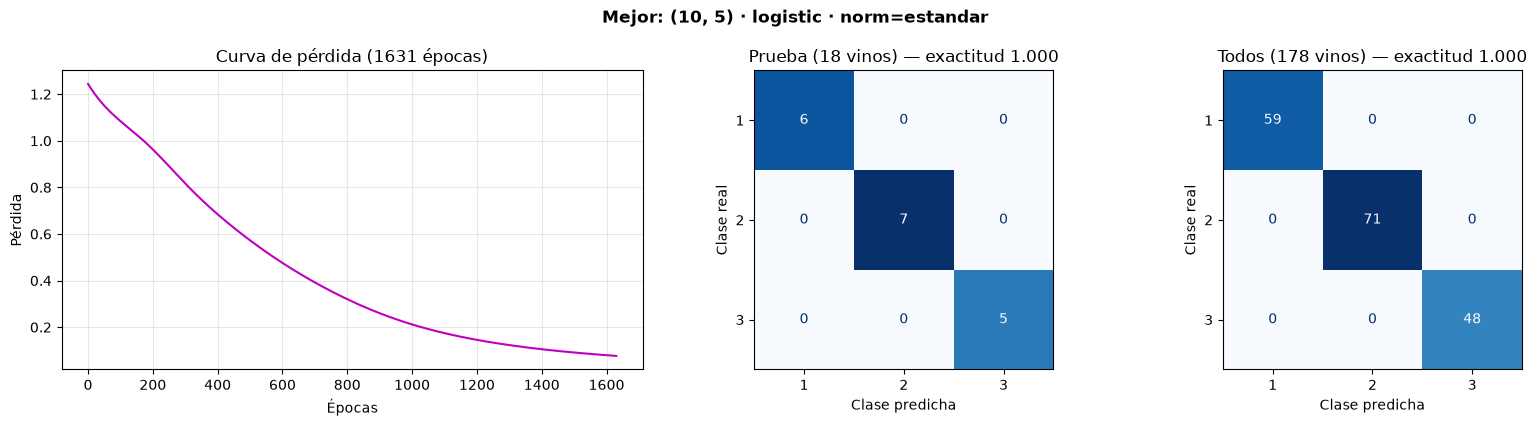

Reporte por clase en prueba:
              precision    recall  f1-score   support

           1      1.000     1.000     1.000         6
           2      1.000     1.000     1.000         7
           3      1.000     1.000     1.000         5

    accuracy                          1.000        18
   macro avg      1.000     1.000     1.000        18
weighted avg      1.000     1.000     1.000        18



In [18]:
f_b, red_bv = caso_v(nombre_v('Mejor', mejor_v), mejor_v)

##### Caso 2: código base sin normalizar

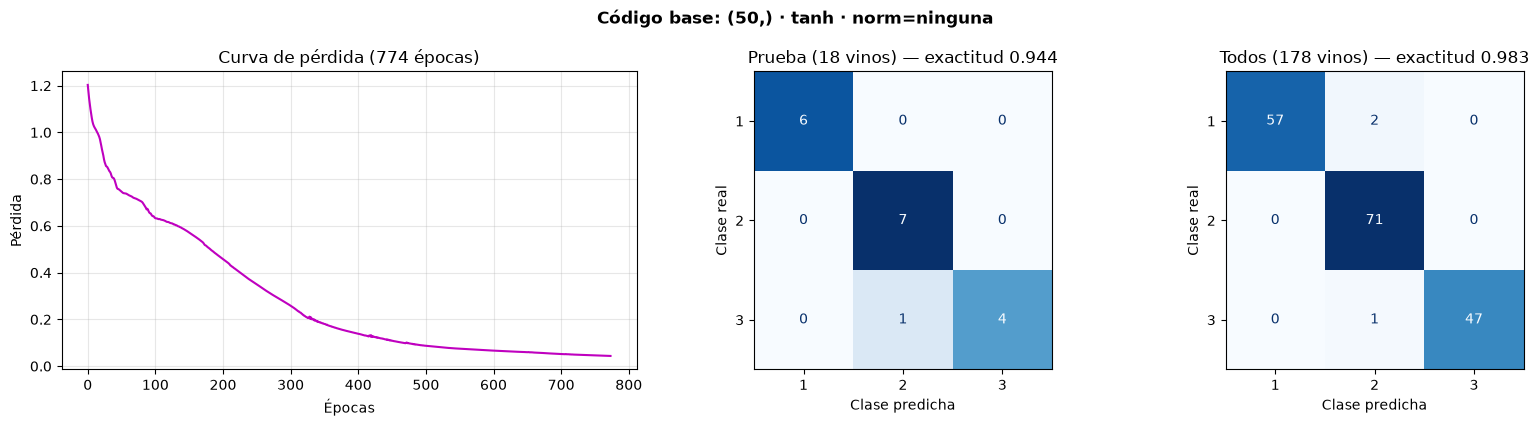

Reporte por clase en prueba:
              precision    recall  f1-score   support

           1      1.000     1.000     1.000         6
           2      0.875     1.000     0.933         7
           3      1.000     0.800     0.889         5

    accuracy                          0.944        18
   macro avg      0.958     0.933     0.941        18
weighted avg      0.951     0.944     0.943        18



In [19]:
f_c, red_cv = caso_v(nombre_v('Código base', base_v), base_v)

##### Caso 3: bajo desempeño / convergencia desfavorable

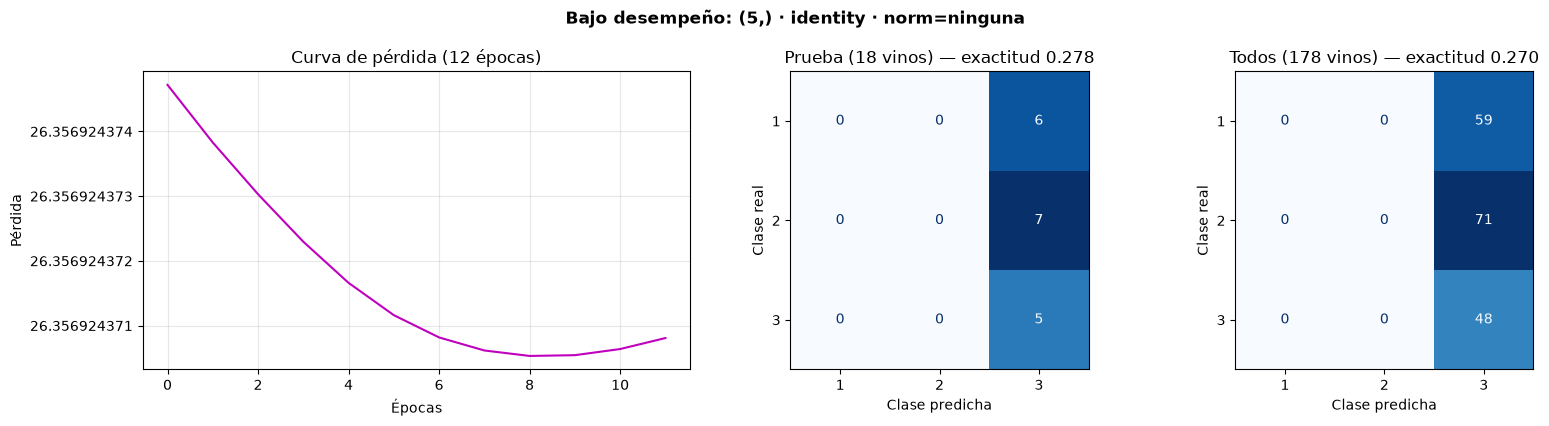

Reporte por clase en prueba:
              precision    recall  f1-score   support

           1      0.000     0.000     0.000         6
           2      0.000     0.000     0.000         7
           3      0.278     1.000     0.435         5

    accuracy                          0.278        18
   macro avg      0.093     0.333     0.145        18
weighted avg      0.077     0.278     0.121        18



In [20]:
f_m, red_mv = caso_v(nombre_v('Bajo desempeño', malo_v), malo_v)

#### ¿Qué clases se confunden con mayor frecuencia?

Se suman las matrices de confusión de los 178 vinos de **todas** las corridas (20 configuraciones × 5 semillas por cada normalización), y se cuentan los errores de cada par (clase real → clase predicha).

In [21]:
for n in norms_v:
    cm = cm_acum[n]
    errores = {f'{clases[i]} → {clases[j]}': cm[i, j] for i in range(3) for j in range(3) if i != j}
    tot = sum(errores.values())
    print(f'--- Normalización: {n} | errores totales: {tot} de {cm.sum()} predicciones '
          f'({100 * tot / cm.sum():.1f} %) ---')
    display(pd.DataFrame(cm, index=[f'Real {c}' for c in clases], columns=[f'Pred {c}' for c in clases]))
    print('Pares más confundidos:', ', '.join(f'{k}: {v}' for k, v in
                                               sorted(errores.items(), key=lambda kv: -kv[1])[:3]))

--- Normalización: ninguna | errores totales: 6286 de 17800 predicciones (35.3 %) ---


,Pred 1,Pred 2,Pred 3
Real 1,3554,1774,572
Real 2,974,5528,598
Real 3,652,1716,2432


Pares más confundidos: 1 → 2: 1774, 3 → 2: 1716, 2 → 1: 974
--- Normalización: estandar | errores totales: 22 de 17800 predicciones (0.1 %) ---


,Pred 1,Pred 2,Pred 3
Real 1,5897,3,0
Real 2,0,7089,11
Real 3,0,8,4792


Pares más confundidos: 2 → 3: 11, 3 → 2: 8, 1 → 2: 3
--- Normalización: minmax | errores totales: 58 de 17800 predicciones (0.3 %) ---


,Pred 1,Pred 2,Pred 3
Real 1,5880,20,0
Real 2,0,7063,37
Real 3,0,1,4799


Pares más confundidos: 2 → 3: 37, 1 → 2: 20, 3 → 2: 1


#### Clasificación de vinos nuevos

Los dos vinos de ejemplo del código de clase se clasifican con los tres modelos representativos (semilla representativa), aplicando a cada uno su misma normalización.

In [22]:
filas_n = []
for etq, f_, red_ in [('Mejor', f_b, red_bv), ('Código base', f_c, red_cv), ('Bajo desempeño', f_m, red_mv)]:
    pr = red_.predict_proba(f_(X_new))
    for i in range(len(X_new)):
        filas_n.append({'modelo': etq, 'vino nuevo': i + 1, 'clase predicha': red_.classes_[pr[i].argmax()],
                        'P(clase 1)': pr[i, 0], 'P(clase 2)': pr[i, 1], 'P(clase 3)': pr[i, 2]})
display(pd.DataFrame(filas_n).set_index(['modelo', 'vino nuevo']).round(3))

# Referencia: vino original más parecido a cada vino nuevo (distancia en variables estandarizadas)
sc_ref = StandardScaler().fit(Xv)
for i, xn in enumerate(X_new, 1):
    d = np.linalg.norm(sc_ref.transform(Xv) - sc_ref.transform(xn.reshape(1, -1)), axis=1)
    print('Vino nuevo %d: el vino original más parecido es de la clase %d (distancia %.2f)' % (i, yv[d.argmin()], d.min()))

clase predicha  P(clase 1)  P(clase 2)  P(clase 3)
modelo         vino nuevo                                                    
Mejor          1                        1       0.929       0.066       0.005
               2                        3       0.008       0.052       0.941
Código base    1                        1       0.993       0.007       0.000
               2                        3       0.000       0.005       0.995
Bajo desempeño 1                        3       0.000       0.000       1.000
               2                        3       0.000       0.000       1.000

Vino nuevo 1: el vino original más parecido es de la clase 1 (distancia 3.14)
Vino nuevo 2: el vino original más parecido es de la clase 3 (distancia 1.64)


<a id="p4-analisis"></a>

### 3.5 Análisis y conclusiones de la práctica

**La división de los datos importa antes que el modelo.** En el Experimento 1, con el corte del código base, los 18 vinos de prueba son todos de la clase 3, y en el entrenamiento solo hay 30 de los 48 vinos de esa clase. Las métricas salen perfectas (exactitud y F1 de 1.000), pero solo evalúan una clase: no dicen nada sobre las clases 1 y 2. Con la división estratificada (6, 7 y 5 vinos de prueba), la misma red baja a 0.944 de exactitud. Esa es la medida honesta de su desempeño.

**La normalización es el factor decisivo.** Sin normalizar, el F1 macro promedio va de 0.357 (`identity`) a 0.699 (`logistic`). Con estandarización llega a 0.988-1.000 y con min-max a 1.000 en todas las configuraciones. La razón es la escala de las variables: la prolina vale cientos o miles y el tono vale alrededor de 1, así que sin normalizar la prolina domina la suma ponderada de cada neurona y las demás variables casi no influyen. **32 de las 60 configuraciones** obtienen F1 macro = 1.0 en prueba, y todas ellas usan datos normalizados.

**Efecto de la arquitectura y la activación.** Con datos normalizados, el problema es casi linealmente separable. Incluso `identity` (equivalente a una regresión logística multiclase) alcanza un F1 macro de 0.996 con estandarización, y la arquitectura casi no importa (0.989 a 1.000). Sin normalizar, las diferencias son grandes y no siguen un patrón simple. Las redes con una capa ancha (`(50,)`: 0.694; `(50,25)`: 0.654) toleran mejor la escala que las pequeñas (`(5,)`: 0.450; `(10,5)`: 0.372). Con `logistic` y `tanh` sin normalizar, solo las redes de 50 neuronas llegan a 0.94, mientras que con `relu` el resultado depende mucho de la semilla.

**Curvas de pérdida de los casos representativos.**
- **Mejor modelo** (`(10,5)`, `logistic`, estandarización, 213 parámetros): la pérdida baja de forma suave y continua desde ~1.2 hasta ~0.08 en ~1,600 épocas, sin oscilaciones. Clasifica correctamente los 18 vinos de prueba y los 178 del conjunto completo. Hubo 32 empates con F1 = 1.0 en prueba; esta configuración se eligió porque también acierta el 100 % de los 178 vinos en las 5 semillas.
- **Código base sin normalizar** (`(50,)`, `tanh`): la pérdida empieza en un valor parecido (~1.2) y también baja, pero de forma más irregular, con pequeños saltos, señal de que algunas neuronas trabajan saturadas por la escala de la prolina. Termina con exactitud de 0.944 en prueba (un vino de la clase 3 clasificado como clase 2) y 0.983 en el total: 2 vinos de la clase 1 y 1 de la clase 3 se clasifican como clase 2.
- **Bajo desempeño** (`(5,)`, `identity`, sin normalizar): la pérdida empieza en ~26.36 y solo cambia en la novena cifra decimal (la gráfica tiene que mostrar 9 decimales para que se note la variación). Como no mejora más de $10^{-4}$ en 10 épocas seguidas, Adam se detiene a las 12 épocas (40 en promedio). La red asigna **todos los vinos a la clase 3** (exactitud de 0.278 en prueba y 0.270 en total; F1 macro promedio de 0.125). Es un caso de convergencia desfavorable: con prolinas de cientos, los valores de salida son enormes, la softmax se satura en 0 y 1, y con la tasa de aprendizaje de 0.001 Adam no logra salir de esa zona antes de que se active el criterio de paro.

**¿Qué clases se confunden más?** Se sumaron las matrices de confusión de todas las corridas:
- **Sin normalizar**, el 35.3 % de las predicciones son erróneas, y los errores más frecuentes son **clase 1 → clase 2** (1,774) y **clase 3 → clase 2** (1,716). Cuando la red no aprende bien, tiende a asignar la clase 2, que es la más numerosa (71 de 178 vinos). Le sigue clase 2 → clase 1 (974).
- **Con datos normalizados**, los errores bajan al 0.1 % (estandarización) y al 0.3 % (min-max). Los pocos que quedan son **clase 2 → clase 3** (11 y 37) y **clase 1 → clase 2** (3 y 20). Las clases **1 y 3 nunca se confunden entre sí**. Químicamente son las más distintas, y la clase 2 queda en la frontera con ambas, así que todas las confusiones involucran a la clase 2.

**Vinos nuevos.** El mejor modelo clasifica el **vino nuevo 1 como clase 1** ($p = 0.929$) y el **vino nuevo 2 como clase 3** ($p = 0.941$). El código base coincide, con más seguridad (0.993 y 0.995), y en los dos casos el vino original más parecido es de esa misma clase. El modelo de bajo desempeño asigna ambos vinos a la clase 3, lo mismo que hace con todos los datos.

**Limitaciones.** El conjunto de prueba tiene solo 18 vinos, así que un solo error cambia la exactitud en 5.6 puntos. Por eso hay tantos empates en 1.0 y conviene ver también la exactitud en los 178 vinos y las matrices acumuladas. Para comparar mejor a los mejores modelos haría falta validación cruzada estratificada.

<a id="conclusiones"></a>

## 4. Conclusiones

<a id="conclusiones-personales"></a>

### 4.1 Conclusiones personales

**Dayanni**

Al preparar el marco teórico de estas dos prácticas me di cuenta de que pasar de regresión a clasificación no cambia la idea del MLP, sino la última capa y la forma de medir el error. Con una neurona logística la red da la probabilidad de la clase 1, con softmax reparte la probabilidad entre las tres clases de vinos, y en los dos casos la entropía cruzada castiga más a la red cuando está muy segura de una respuesta equivocada. También me ayudó entender por qué la activación `identity` da una frontera recta: toda la red se vuelve una regresión logística, y eso explica que en la Práctica 3 siempre se quedara en un F1 de 0.917, mientras que las activaciones no lineales con datos normalizados llegaron casi a 1. Otra cosa que aprendí es que la escala de los datos importa mucho; en los vinos, la prolina vale cientos y el tono vale alrededor de 1, así que sin normalizar una sola variable puede dominar a la red. Por último, me quedó claro que la exactitud por sí sola puede engañar, que hay que revisar la matriz de confusión y las métricas por clase, y que también hay que fijarse en cómo se dividen los datos, porque si vienen ordenados por clase el conjunto de prueba puede no representar a todas las clases.

**Valeria Esmer**

En esta práctica aprendí que el desempeño de una red neuronal no depende únicamente de su tamaño, sino principalmente de cómo se preparan los datos. Pude observar que una misma arquitectura con activación logistic pasó de clasificar todas las muestras como clase 1 a obtener resultados perfectos simplemente al normalizar las variables. Esto también me permitió comprobar que una red pequeña de cinco neuronas puede ser suficiente, sin necesidad de agregar más capas o neuronas.

También comprendí que no basta con revisar la exactitud o el recall para determinar si un modelo funciona correctamente, ya que pueden dar una impresión equivocada de su desempeño. Por ejemplo, el modelo de bajo rendimiento obtuvo un recall de 1.00, pero en realidad clasificaba todos los puntos como clase 1. Por eso es importante analizar también la matriz de confusión, la precisión y el F1.

Finalmente, considero que los resultados deben tomarse con cierta precaución, porque se trabajó con solo 100 datos y la evaluación incluyó muestras utilizadas durante el entrenamiento. Para comprobar mejor la capacidad de generalización sería necesario utilizar más datos o aplicar validación cruzada. En general, esta práctica me ayudó a entender la importancia de normalizar las variables, elegir una función de activación adecuada y buscar modelos sencillos que ofrezcan buenos resultados sin agregar complejidad innecesaria.

**Fernanda**

Me tocó programar y probar la Práctica 4. Lo que más me llamó la atención fue que el primer resultado "perfecto" era engañoso: con la división del código base, todos los vinos de prueba eran de la clase 3, y el 100 % de exactitud no decía nada de las otras dos clases. Revisar cómo vienen ordenados los datos antes de entrenar fue tan importante como elegir la red. También vi que la normalización hace toda la diferencia. Sin ella, la prolina domina a las demás variables, algunas redes se quedan atoradas desde las primeras épocas y terminan asignando todos los vinos a una sola clase; con ella, casi cualquier arquitectura, incluso una lineal, clasifica bien. La curva de pérdida me sirvió para distinguir una red que aprende despacio de una que nunca empezó a aprender. La matriz de confusión me ayudó a entender qué pasaba en cada caso: las clases 1 y 3 nunca se confunden y casi todos los errores involucran a la clase 2.

**Estephany**

Mi parte fue revisar e integrar el reporte. Al volver a ejecutar todo el notebook, algunos números del análisis de la Práctica 3 ya no coincidían exactamente con las tablas, y hubo que actualizarlos. También acomodé los casos de prueba dentro de la sección de resultados, que es donde correspondían. Aprendí que un reporte técnico tiene que poder ejecutarse de principio a fin y que cada afirmación del análisis debe salir de una tabla. Revisar las dos prácticas juntas me ayudó a ver la idea que las une: el MLP funciona muy bien para clasificar, pero solo si los datos están bien preparados. La normalización y una buena división entre entrenamiento y prueba importaron más que el tamaño de la red, y la matriz de confusión fue la herramienta que mejor mostró cuándo un modelo realmente funcionaba y cuándo solo lo parecía.

<a id="conclusiones-generales"></a>

### 4.2 Conclusiones generales

En las dos prácticas se usó `MLPClassifier` con la misma idea, una capa de salida que convierte la red en un clasificador (una neurona logística para dos clases y softmax para tres) y entropía cruzada como pérdida. En cada práctica se probaron **60 configuraciones**, combinando 5 arquitecturas, 4 activaciones y 3 tipos de normalización.

| Aspecto | Práctica 3 (binaria, `data1.txt`) | Práctica 4 (multiclase, `vinos.txt`) |
|---|---|---|
| Datos | 100 muestras, 2 variables (30-100), 2 clases | 178 vinos, 13 variables (escalas de 0.1 a ~1,700), 3 clases |
| Entrenamiento | L-BFGS, 1 semilla | Adam, 5 semillas, división estratificada |
| Mejor modelo | `(5,)`, `logistic`, min-max (21 parámetros) | `(10,5)`, `logistic`, estandarización (213 parámetros) |
| Desempeño del mejor | Exactitud y F1 = 1.00 (100 muestras) | Exactitud y F1 macro = 1.00 (prueba y 178 vinos) |
| Peor caso | `(10,)`, `logistic`, sin normalizar: todo clase 1 (exactitud 0.60) | `(5,)`, `identity`, sin normalizar: todo clase 3 (exactitud 0.28) |
| F1 promedio sin / con normalización | 0.922 / 0.975 | 0.541 / 0.997 (macro) |

**Coincidencias.**
1. **La normalización es el factor más importante.** En las dos prácticas, el peor modelo fue uno sin normalizar que **asigna todas las muestras a una sola clase**, con la pérdida estancada desde el inicio. Al normalizar, casi todas las configuraciones llegan a F1 cercano a 1. El efecto es mucho mayor en los vinos (F1 macro de 0.54 a 0.997) que en `data1.txt` (0.92 a 0.975), porque allí las escalas de las variables son mucho más distintas entre sí.
2. **Redes pequeñas son suficientes.** En ninguna práctica la arquitectura más grande fue la mejor. Con datos normalizados, las diferencias entre arquitecturas son mínimas, y redes de 5 a 10 neuronas por capa resuelven los dos problemas.
3. **La exactitud sola puede engañar.** En la Práctica 3, el peor modelo tiene recall de 1.00 aunque no distingue nada. En la Práctica 4, la división ordenada da 100 % de exactitud evaluando una sola clase. La matriz de confusión y las métricas por clase fueron indispensables en ambos casos.

**Diferencias entre clasificación binaria y multiclase.**
1. **Forma de la frontera.** En `data1.txt` las clases se mezclan en una zona, y una frontera recta (`identity`) se queda en F1 = 0.917: se necesita una activación no lineal. En los vinos, con datos normalizados, las tres clases son casi linealmente separables en 13 dimensiones, e incluso `identity` llega a F1 macro de 0.996.
2. **Qué se puede graficar.** Con 2 variables se puede ver la frontera de decisión en el plano y entender los errores visualmente. Con 13 variables hay que apoyarse en la curva de pérdida y la matriz de confusión, que además muestra **qué clases se confunden**: en los vinos siempre es la clase 2 con alguna de las otras, nunca la 1 con la 3.
3. **Métricas.** En el caso binario basta con precisión, recall y F1 de la clase positiva. En el multiclase hay que reportar cada clase y resumir con promedios macro y weighted. Como las clases de vinos están balanceadas, ambos promedios quedan muy cerca.
4. **Optimizador y convergencia.** L-BFGS (Práctica 3) converge en pocas iteraciones con datos pequeños. Adam (Práctica 4) necesita cientos o miles de épocas y depende más de la escala de los datos: sin normalizar, su criterio de paro puede detenerlo en la época 12 sin haber aprendido nada.

**Conclusión final.** El MLP resolvió con éxito los dos problemas de clasificación, pero los resultados dependieron menos del tamaño de la red que de **preparar bien los datos**: normalizar las variables, revisar cómo vienen ordenadas y separar el conjunto de prueba de forma que represente a todas las clases. Como los conjuntos de prueba son pequeños (10 y 18 muestras), los resultados perfectos deben tomarse con precaución. El siguiente paso para comparar modelos de forma más sólida sería la validación cruzada estratificada.